# Importation des packages

In [41]:
# Importation des bibliothèques nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [42]:

# Importation des données
data = pd.read_csv("boston.csv",index_col=0)

data.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [43]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 1 to 506
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       506 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  black    506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [44]:

# Renommage des colonnes 
data.columns = ["Taux_criminalite", "Prop_terrains_resid", "Prop_acres_indus", "Bordure_riviere", "Concentration_NO2",
                "Nb_pieces_logement", "Prop_log_construits_av1940", "Dist_ponderees_emploi", "Accessibilite_autoroute",
                "Taux_impot_foncier", "Ratio_eleve_prof", "Prop_noirs_ville", "Pourcentage_pop_inf", "Valeur_med_logement"]



# Affichage des 5 premières lignes de la base de données avec les noms de colonnes renommés
data.head()


,Taux_criminalite,Prop_terrains_resid,Prop_acres_indus,Bordure_riviere,Concentration_NO2,Nb_pieces_logement,Prop_log_construits_av1940,Dist_ponderees_emploi,Accessibilite_autoroute,Taux_impot_foncier,Ratio_eleve_prof,Prop_noirs_ville,Pourcentage_pop_inf,Valeur_med_logement
1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


1. **Taux_criminalite :** Taux de criminalité par habitant par ville.
2. **Prop_terrains_resid :** Proportion de terrains résidentiels zonés pour des lots de plus de 25 000 pieds carrés.
3. **Prop_acres_indus :** Proportion d'acres industriels non commerciaux par ville.
4. **Bordure_riviere :** Variable fictive Charles River (= 1 si le tronçon borde la rivière ; 0 sinon).
5. **Concentration_NO2 :** Concentration de dioxyde d'azote (parties par 10 millions).
6. **Nb_pieces_logement :** Nombre moyen de pièces par logement.
7. **Prop_log_construits_av1940 :** Proportion de logements occupés par leur propriétaire construits avant 1940.
8. **Dist_ponderees_emploi :** Distances pondérées aux cinq centres d'emploi de Boston.
9. **Accessibilite_autoroute :** Indice d'accessibilité aux autoroutes radiales.
10. **Taux_impot_foncier :** Taux d'impôt foncier sur la valeur totale de la propriété.
11. **Ratio_eleve_prof :** Ratio élève-professeur par ville.
12. **Prop_noirs_ville :** Proportion de la population noire par ville.
13. **Pourcentage_pop_inf :** Pourcentage de statut inférieur de la population.
14. **Valeur_med_logement :** Valeur médiane des maisons occupées par leur propriétaire en milliers de dollars

In [45]:
#Valeurs manquantes

data.isnull().sum()

Taux_criminalite              0
Prop_terrains_resid           0
Prop_acres_indus              0
Bordure_riviere               0
Concentration_NO2             0
Nb_pieces_logement            0
Prop_log_construits_av1940    0
Dist_ponderees_emploi         0
Accessibilite_autoroute       0
Taux_impot_foncier            0
Ratio_eleve_prof              0
Prop_noirs_ville              0
Pourcentage_pop_inf           0
Valeur_med_logement           0
dtype: int64

## Analyse sur la base globale

In [46]:
# Résumé statistique des variables
data.describe()

,Taux_criminalite,Prop_terrains_resid,Prop_acres_indus,Bordure_riviere,Concentration_NO2,Nb_pieces_logement,Prop_log_construits_av1940,Dist_ponderees_emploi,Accessibilite_autoroute,Taux_impot_foncier,Ratio_eleve_prof,Prop_noirs_ville,Pourcentage_pop_inf,Valeur_med_logement
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


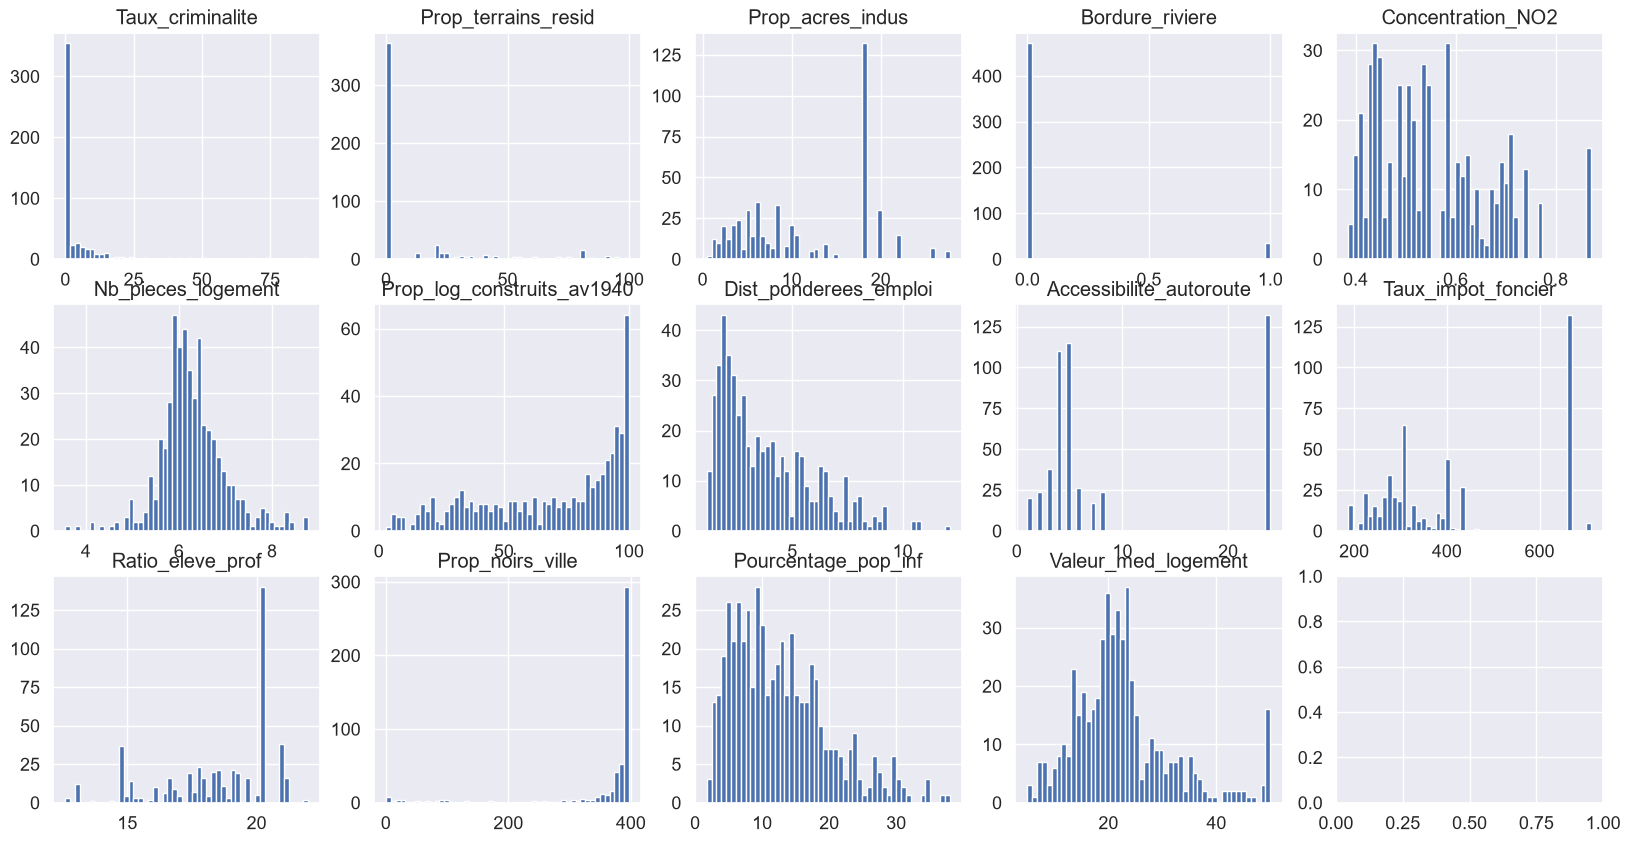

In [47]:
# Visualisation de la distribution des variables
fig, axs = plt.subplots(3, 5, figsize=(20, 10))
axs = axs.ravel()

for i, column in enumerate(data.columns):
    axs[i].hist(data[column], bins=50)
    axs[i].set_title(column)

plt.show()

## Distribution des variables

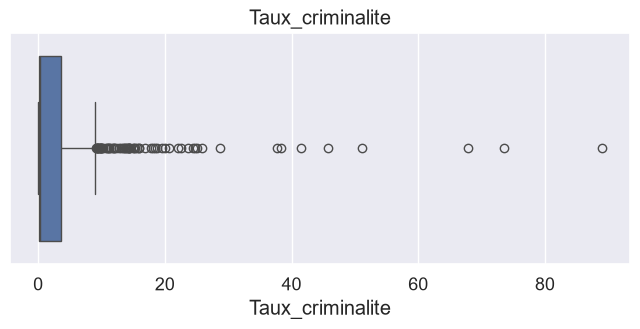

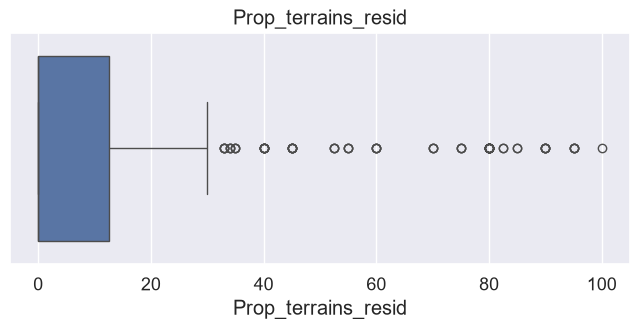

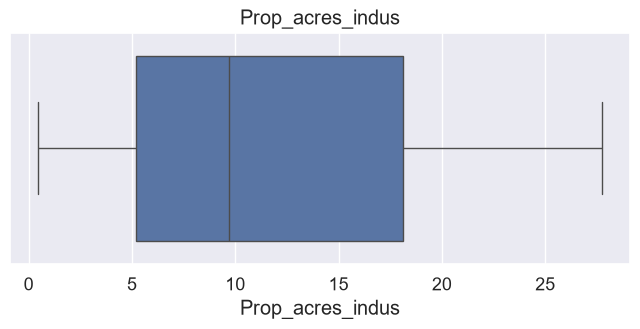

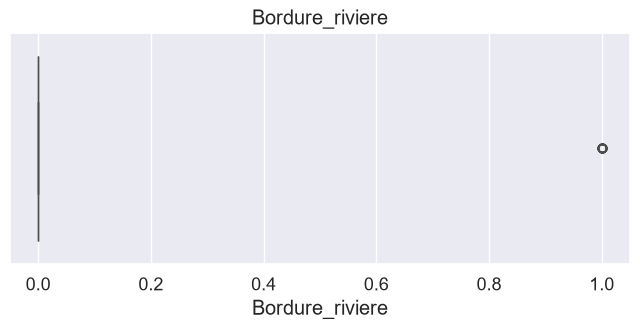

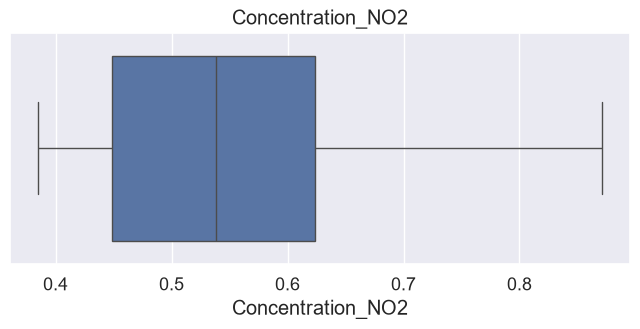

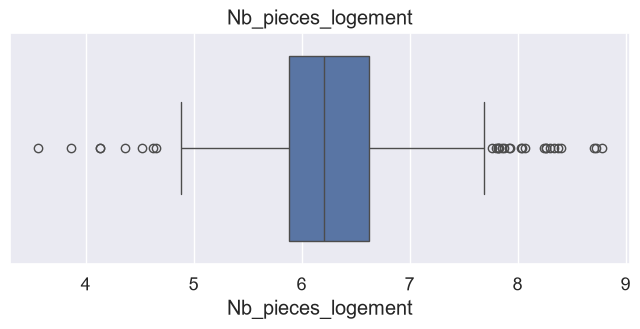

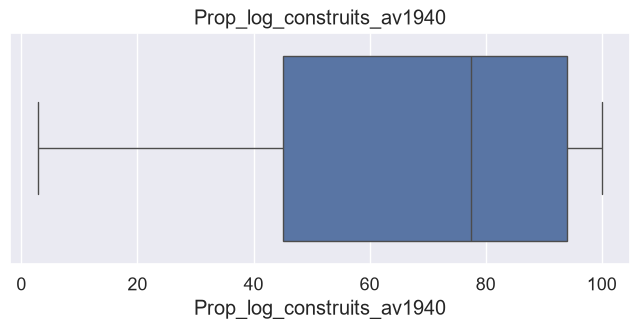

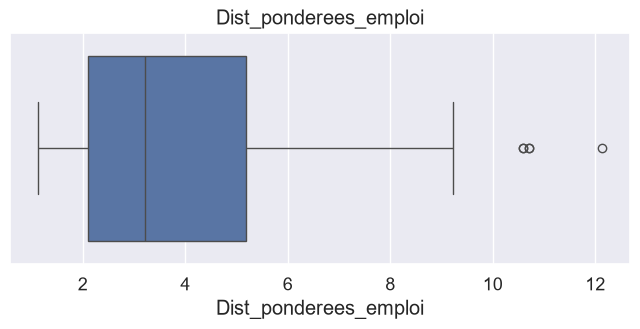

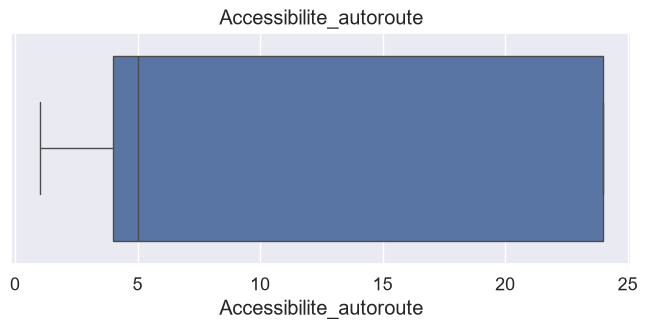

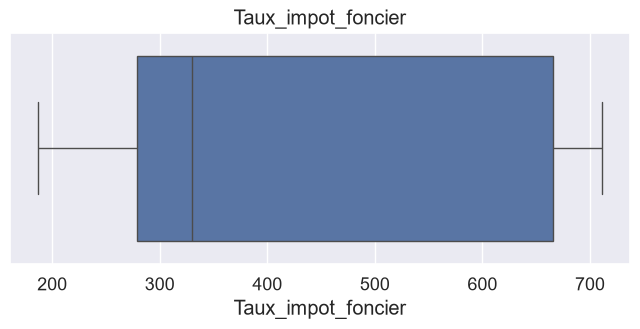

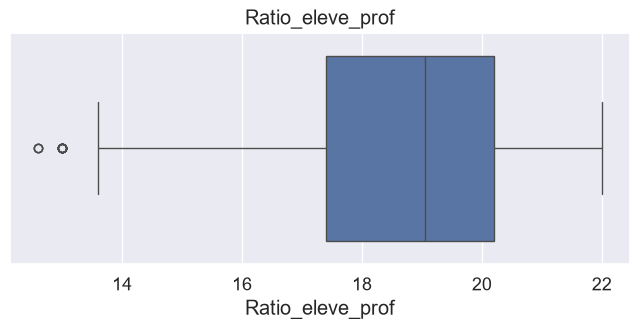

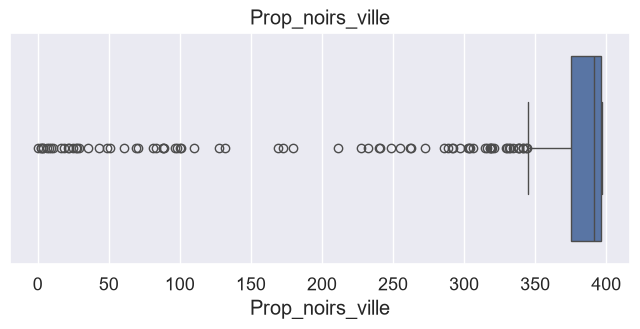

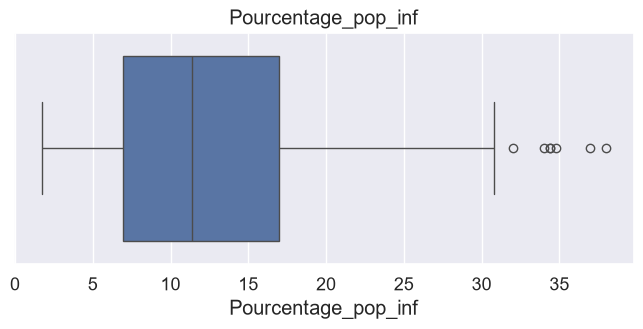

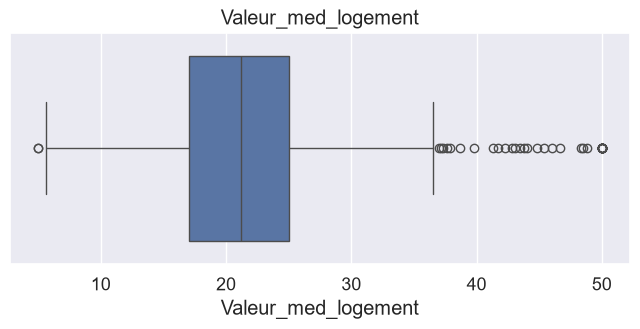

In [48]:
import seaborn as sns

# Tracé des boxplots pour chaque variable
for column in data.columns:
    fig, ax = plt.subplots(figsize=(8, 3))
    sns.boxplot(x=data[column], ax=ax)
    plt.title(column)
    plt.show()

## Corrélation entre les variables

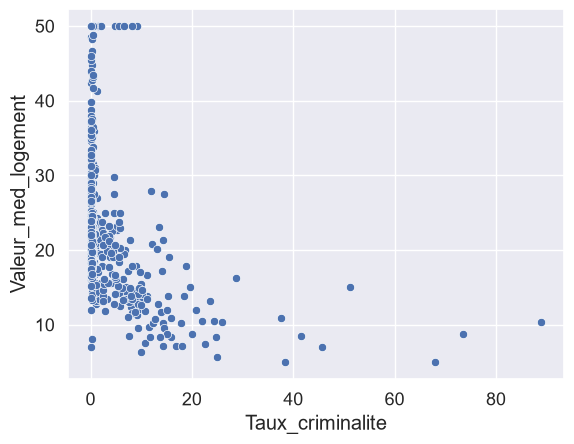

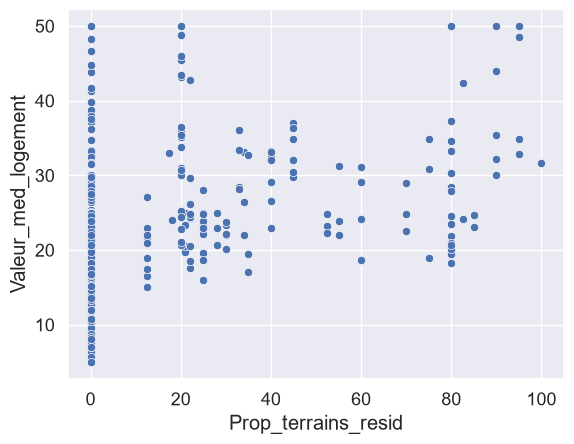

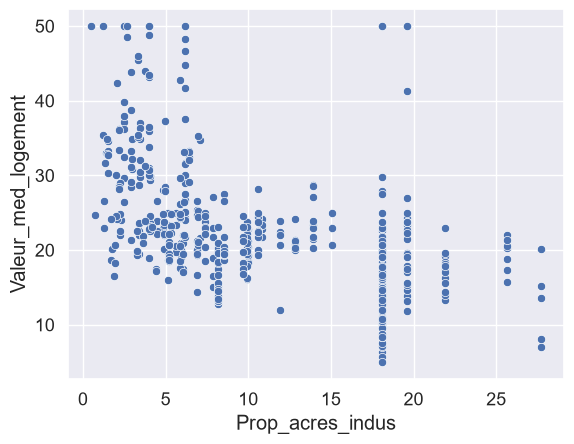

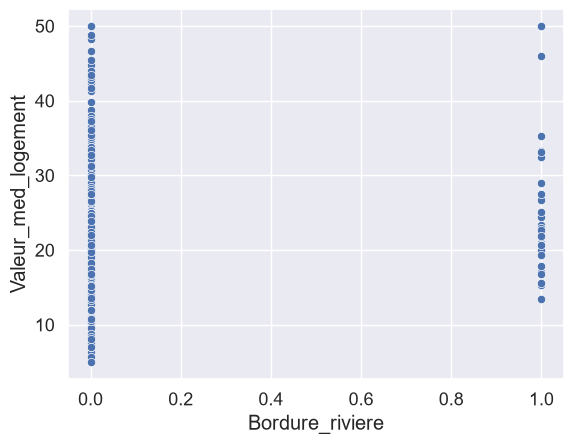

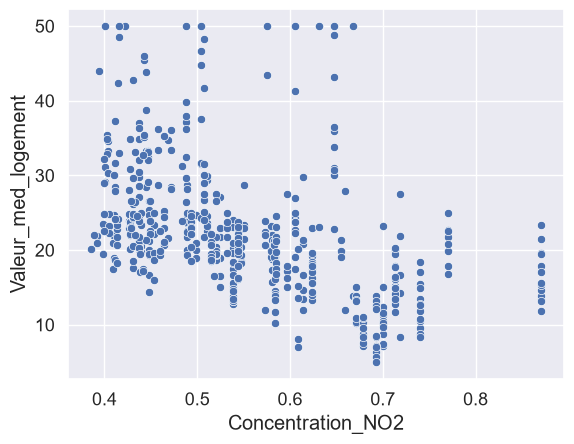

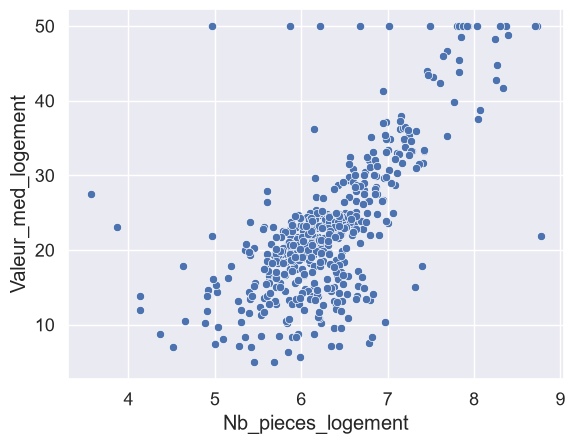

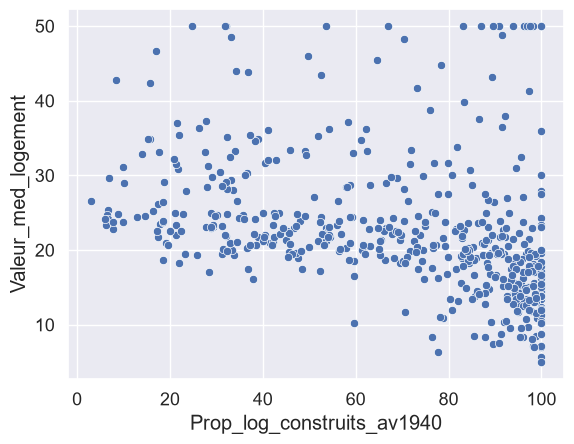

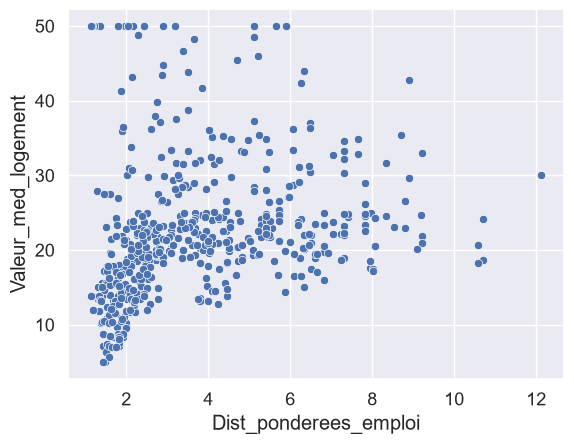

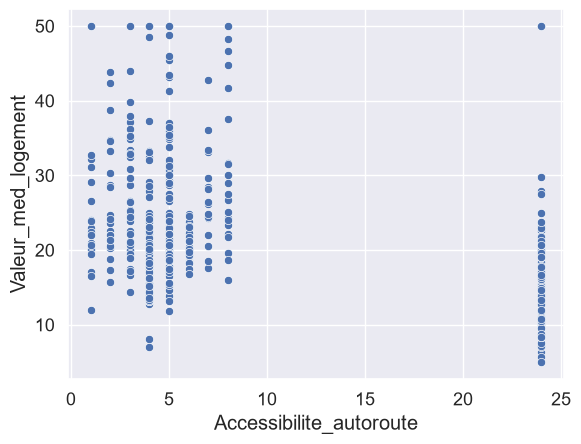

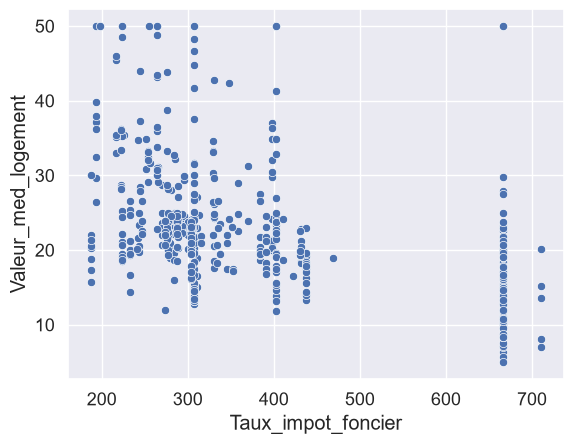

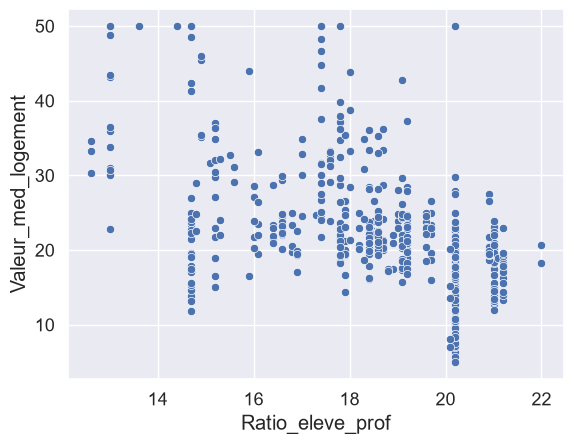

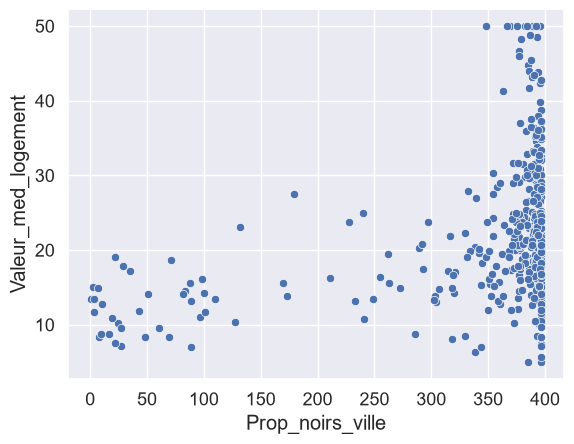

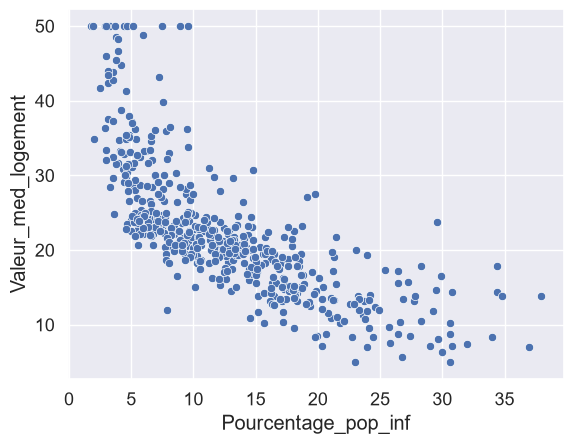

In [ ]:
# Extraction des colonnes de variables explicatives
X = data.drop("Valeur_med_logement", axis=1)

# Affichage des nuages de points entre la variable à expliquer et toutes les variables explicatives avec seaborn
for col in X.columns:
    sns.scatterplot(x=X[col], y=data["Valeur_med_logement"])
    plt.show()

<Axes: >

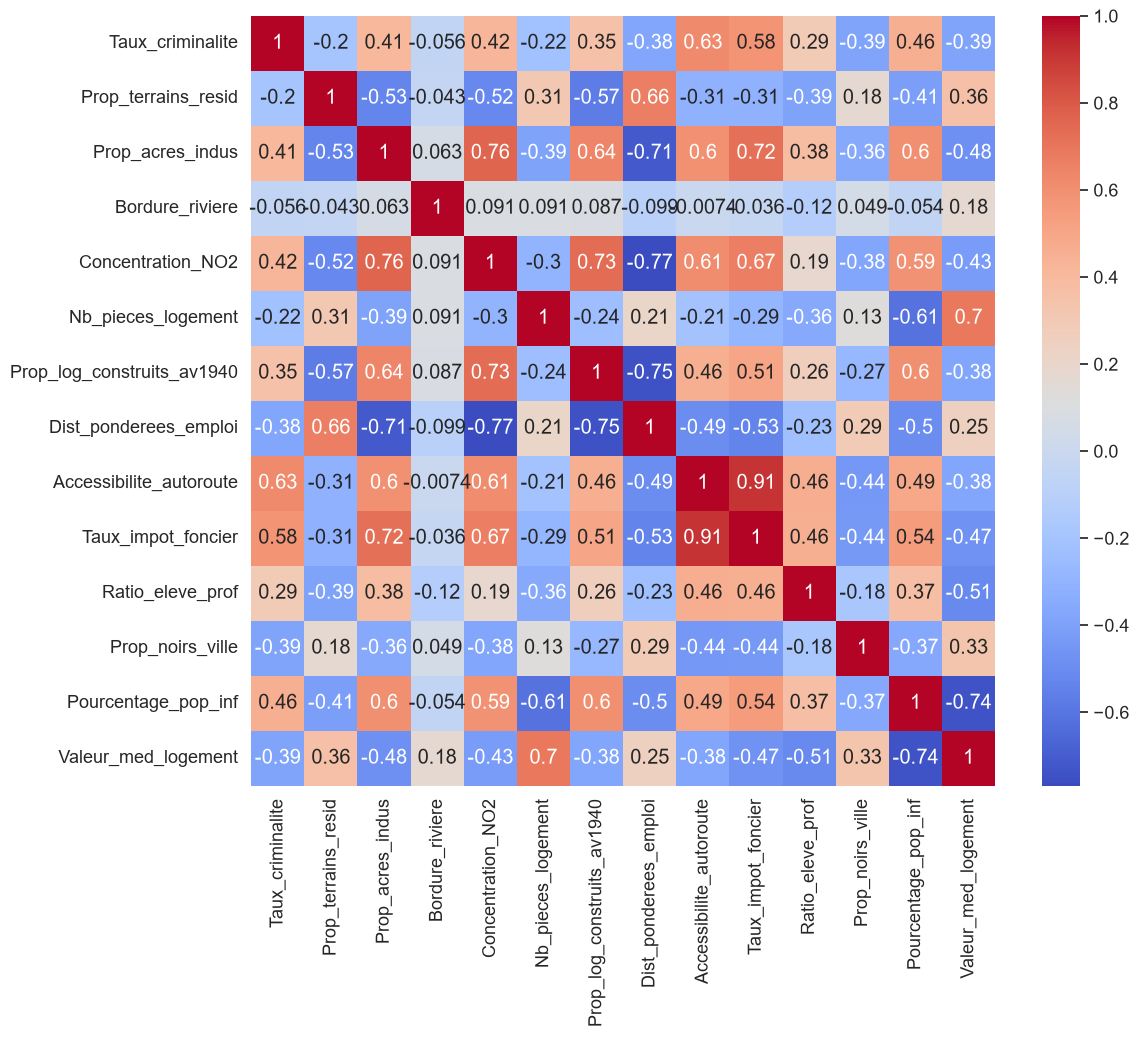

In [50]:
# Calcul de la matrice de corrélation
corr_matrix = data.corr()


plt.figure(figsize=(12, 10))
# Affichage de la matrice de corrélation sous forme de heatmap avec seaborn
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")

In [51]:
# Extraction des variables ayant une corrélation supérieure à 0.6 avec la variable d'intérêt
corr_threshold = 0.6
corr_vars = corr_matrix[abs(corr_matrix["Valeur_med_logement"]) > corr_threshold].index.tolist()

# Affichage des variables ayant une corrélation supérieure à 0.6 avec la variable d'intérêt
print("Variables ayant une corrélation supérieure à 0.6 avec la variable d'intérêt (Valeur_med_logement) :\n")
print(corr_vars)

Variables ayant une corrélation supérieure à 0.6 avec la variable d'intérêt (Valeur_med_logement) :

['Nb_pieces_logement', 'Pourcentage_pop_inf', 'Valeur_med_logement']


In [52]:
# Extraction des variables ayant une corrélation inférieure à -0.6 avec la variable d'intérêt
corr_threshold = -0.6
corr_vars = corr_matrix[abs(corr_matrix["Valeur_med_logement"]) < corr_threshold].index.tolist()

# Affichage des variables ayant une corrélation supérieure à 0.6 avec la variable d'intérêt
print("Variables ayant une corrélation inférieure à -0.6 avec la variable d'intérêt (Valeur_med_logement) :\n")
print(corr_vars)

Variables ayant une corrélation inférieure à -0.6 avec la variable d'intérêt (Valeur_med_logement) :

[]


In [53]:

# Extraction des couples de variables ayant une corrélation supérieure à 0.8
corr_threshold = 0.8
corr_pairs = {}

for col in corr_matrix.columns:
    corr_pairs[col] = []
    corr_values = corr_matrix[abs(corr_matrix[col]) > corr_threshold][col].index.tolist()
    for pair in corr_values:
        if pair != col:
            corr_pairs[col].append(pair)

# Affichage des couples de variables ayant une corrélation supérieure à 0.8
print("Couples de variables ayant une corrélation supérieure à 0.8 :\n")
for col, pairs in corr_pairs.items():
    if len(pairs) > 0:
        for pair in pairs:
            print(col, "-", pair)

Couples de variables ayant une corrélation supérieure à 0.8 :

Accessibilite_autoroute - Taux_impot_foncier
Taux_impot_foncier - Accessibilite_autoroute


In [54]:

# Extraction des couples de variables ayant une corrélation inférieure à -0.8
corr_threshold = -0.8
corr_pairs = {}

for col in corr_matrix.columns:
    corr_pairs[col] = []
    corr_values = corr_matrix[abs(corr_matrix[col]) < corr_threshold][col].index.tolist()
    for pair in corr_values:
        if pair != col:
            corr_pairs[col].append(pair)

# Affichage des couples de variables ayant une corrélation inférieure à -0.8
print("Couples de variables ayant une corrélation inférieure à -0.8 :\n")
for col, pairs in corr_pairs.items():
    if len(pairs) > 0:
        for pair in pairs:
            print(col, "-", pair)

Couples de variables ayant une corrélation inférieure à -0.8 :



# Division en Train et en Test

In [55]:

# Diviser les données en ensembles d'apprentissage et de test

train, test = train_test_split(data, test_size=0.2, random_state=42)



## Sélection des features sur la base train

In [56]:
# Résumé statistique des variables
train.describe()

,Taux_criminalite,Prop_terrains_resid,Prop_acres_indus,Bordure_riviere,Concentration_NO2,Nb_pieces_logement,Prop_log_construits_av1940,Dist_ponderees_emploi,Accessibilite_autoroute,Taux_impot_foncier,Ratio_eleve_prof,Prop_noirs_ville,Pourcentage_pop_inf,Valeur_med_logement
count,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000,404.000000
mean,3.609125,11.569307,10.985050,0.071782,0.556484,6.315891,68.556436,3.808195,9.356436,404.032178,18.318317,356.278342,12.457351,22.796535
std,8.875058,23.152481,6.894618,0.258447,0.117704,0.709452,27.994922,2.131226,8.589721,166.172655,2.228701,91.566533,7.110381,9.332147
min,0.009060,0.000000,0.740000,0.000000,0.385000,3.863000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.081437,0.000000,5.130000,0.000000,0.452000,5.890500,45.550000,2.087875,4.000000,279.000000,16.800000,375.472500,6.772500,16.950000
50%,0.261390,0.000000,8.560000,0.000000,0.538000,6.210000,77.700000,3.175750,5.000000,330.000000,18.700000,391.305000,10.925000,21.600000
75%,3.202962,20.000000,18.100000,0.000000,0.631000,6.636750,93.650000,5.400800,12.000000,666.000000,20.200000,395.755000,16.372500,26.400000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


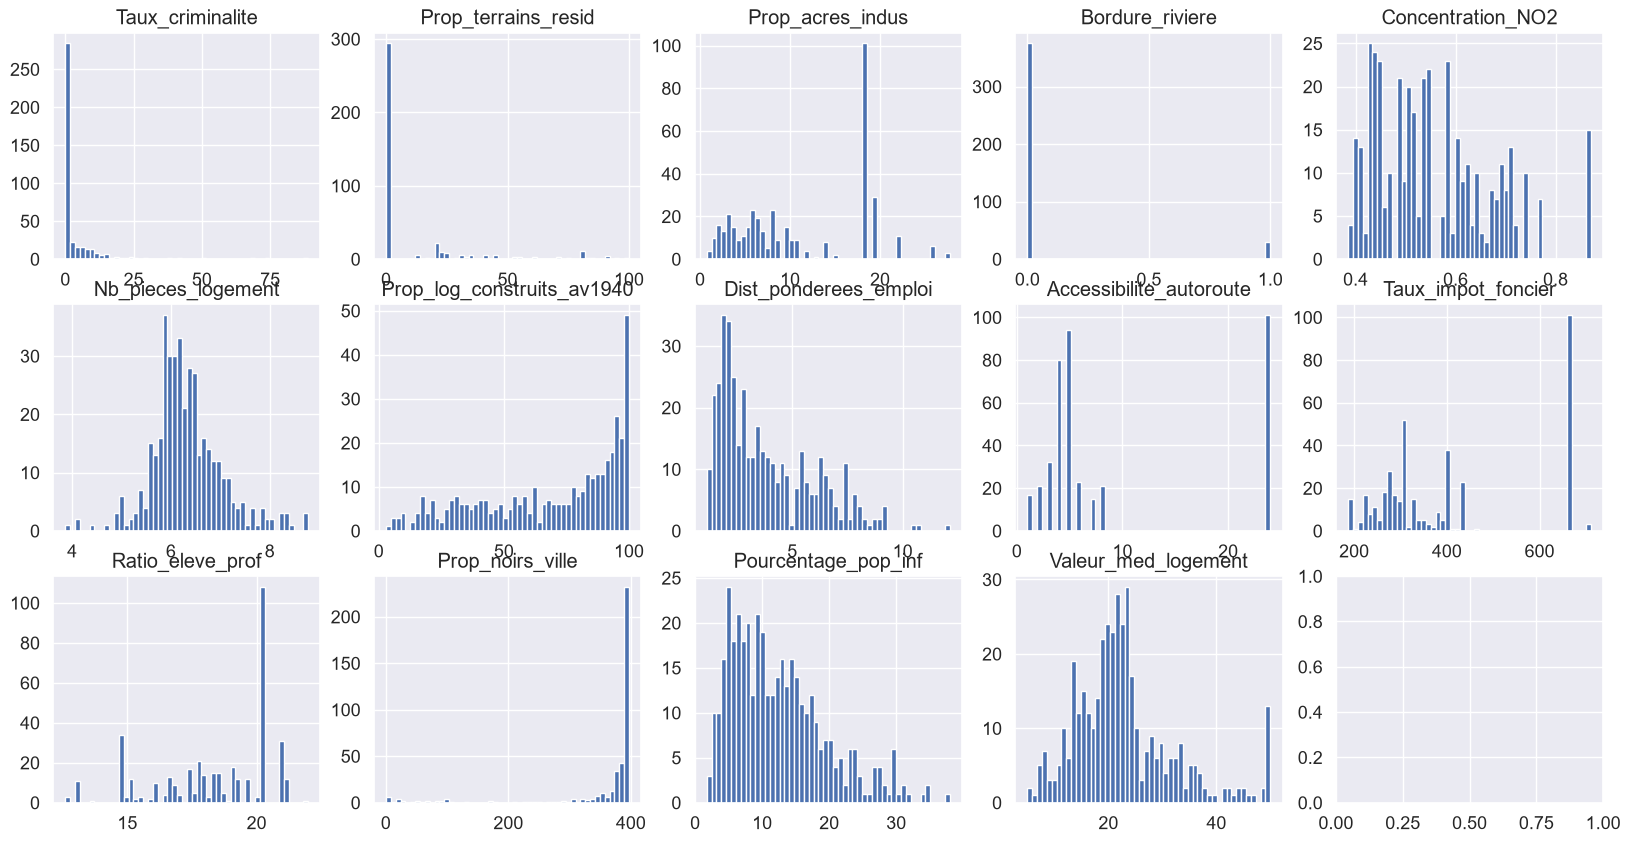

In [57]:
# Visualisation de la distribution des variables
fig, axs = plt.subplots(3, 5, figsize=(20, 10))
axs = axs.ravel()

for i, column in enumerate(train.columns):
    axs[i].hist(train[column], bins=50)
    axs[i].set_title(column)

plt.show()

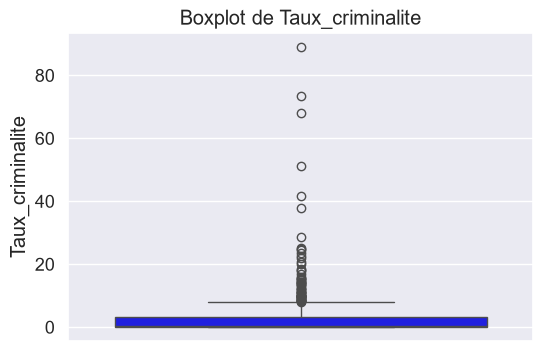

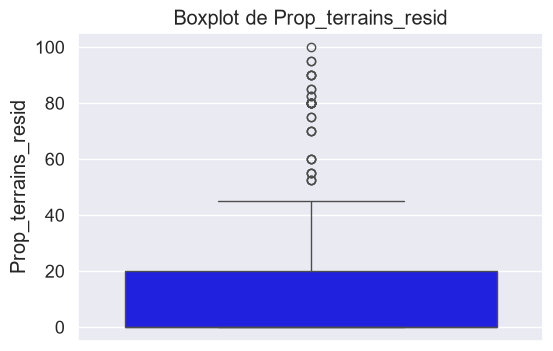

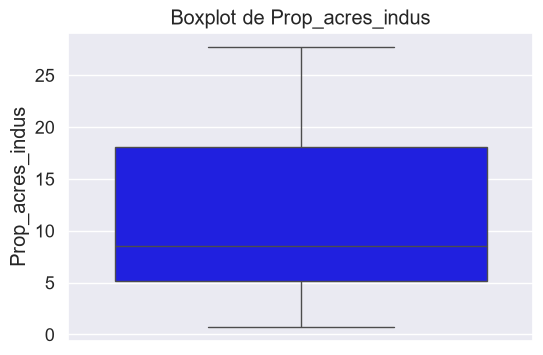

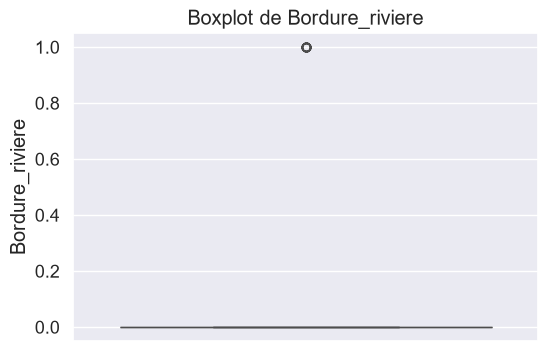

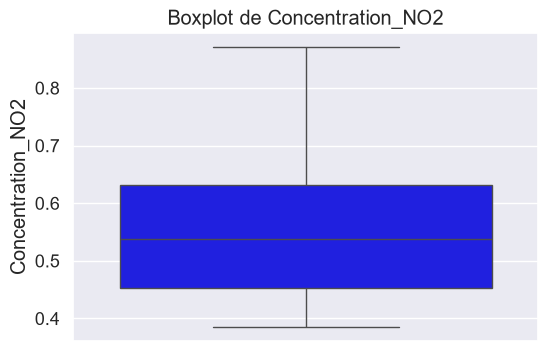

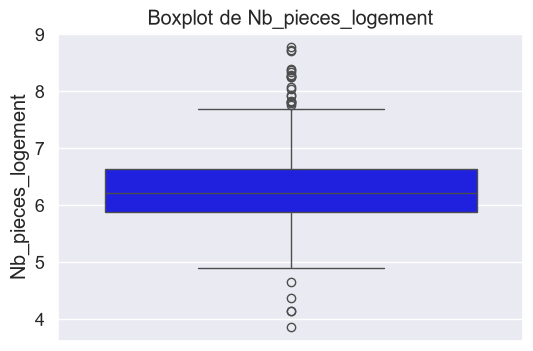

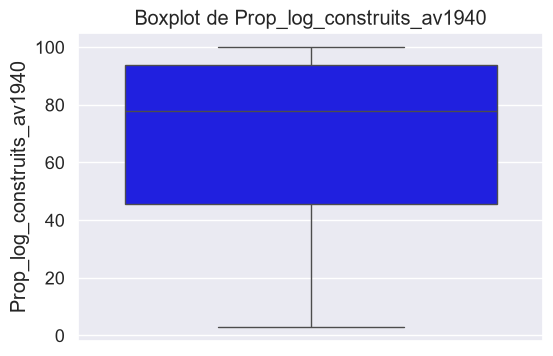

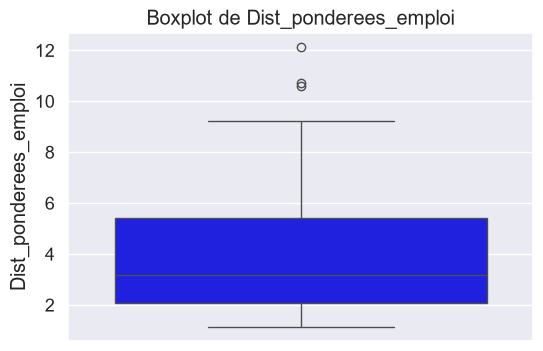

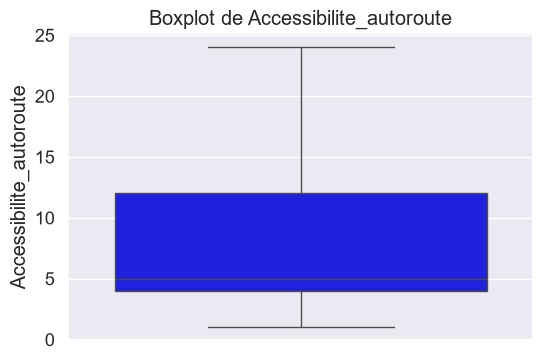

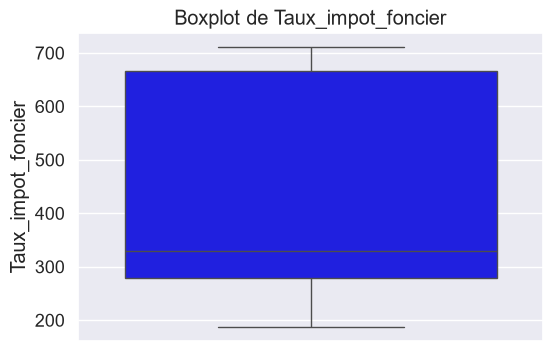

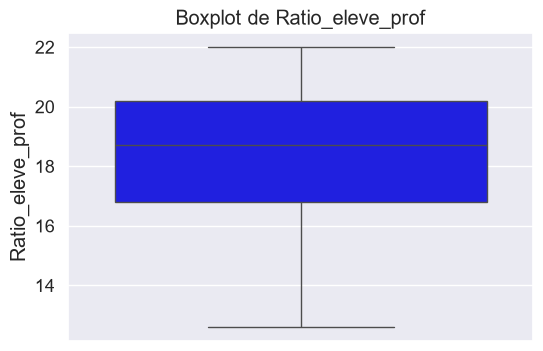

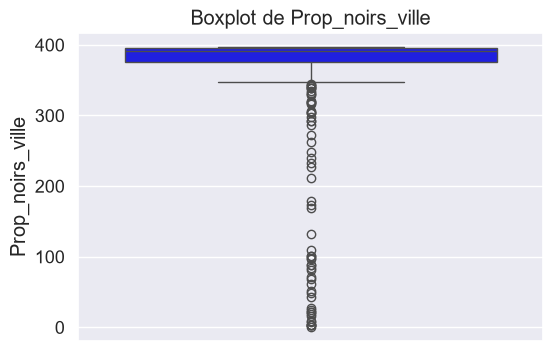

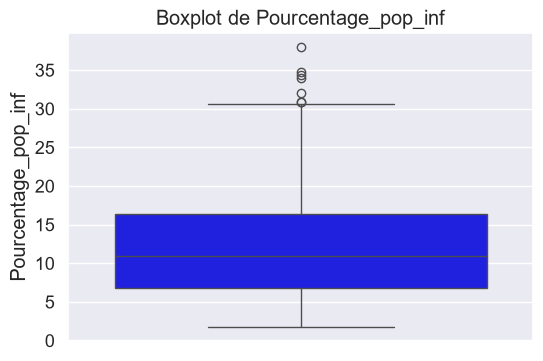

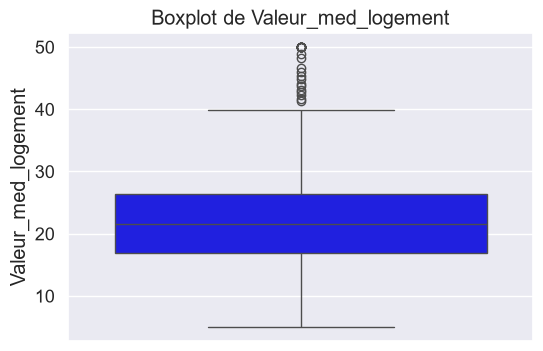

In [58]:

# Affichage des boxplots pour chaque variable numérique
num_cols = list(train.select_dtypes(include=["float64", "int64"]).columns)

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=train, y=col, color="blue")
    plt.title(f"Boxplot de {col}")
    plt.ylabel(col)
    plt.show()

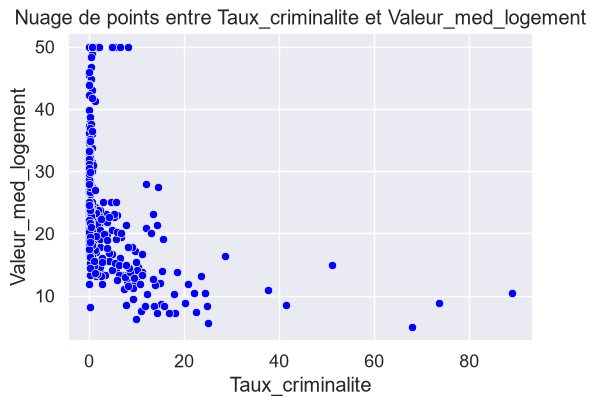

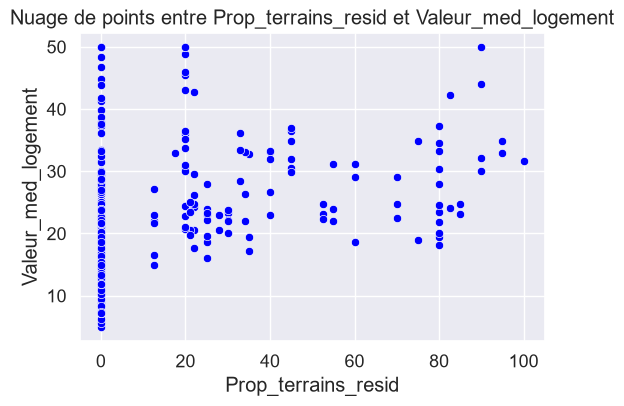

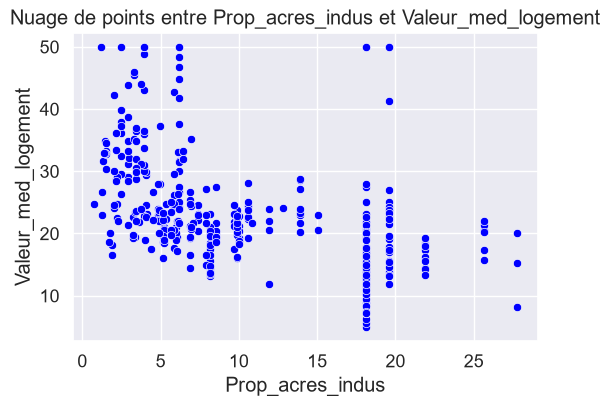

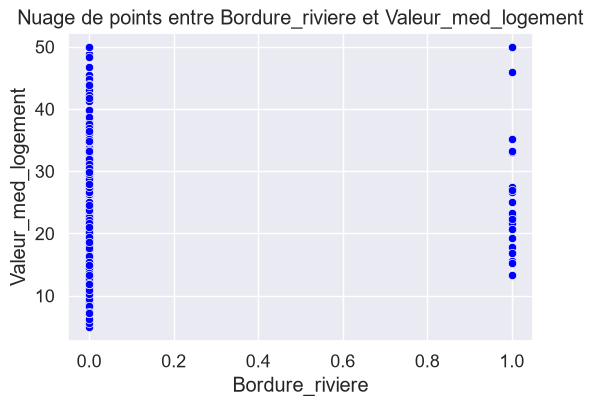

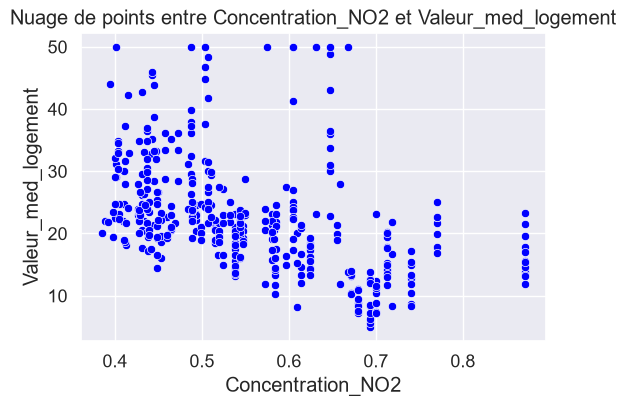

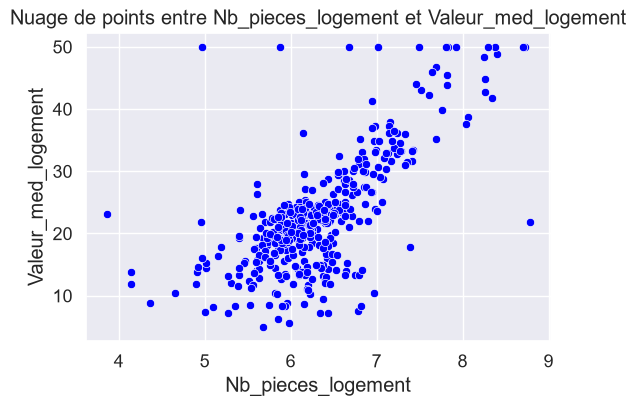

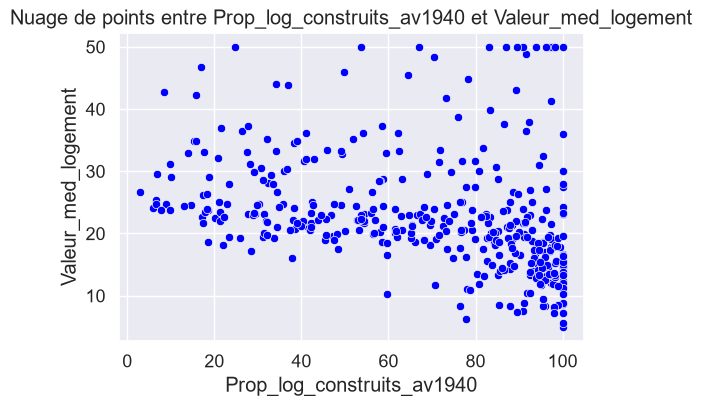

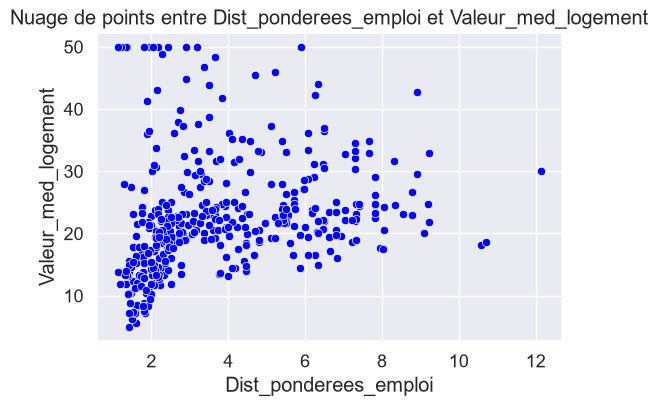

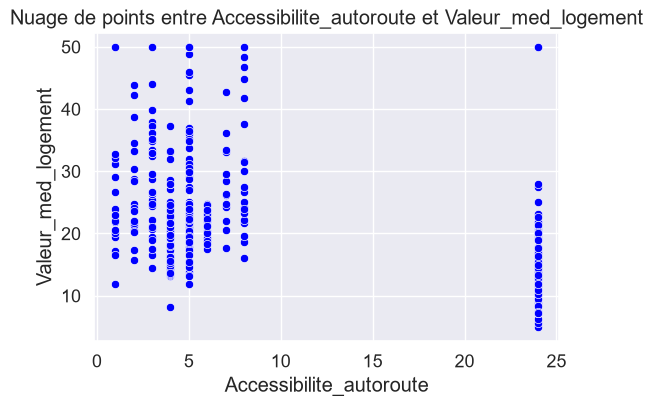

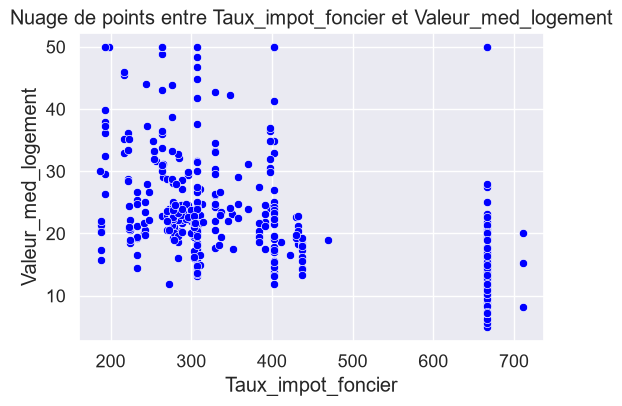

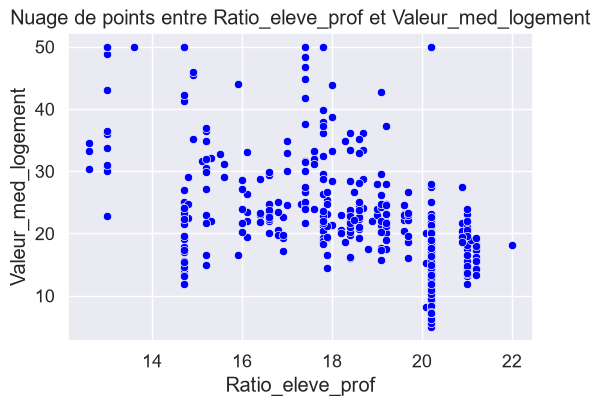

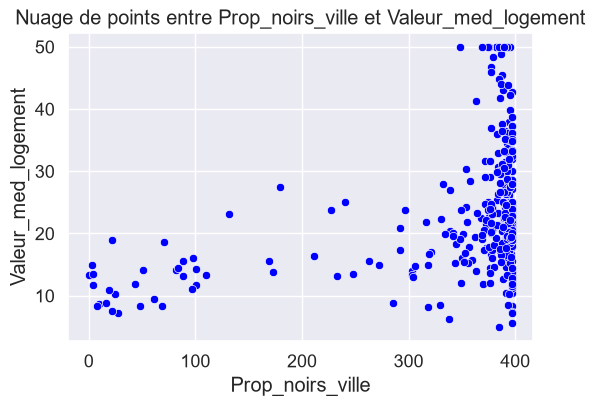

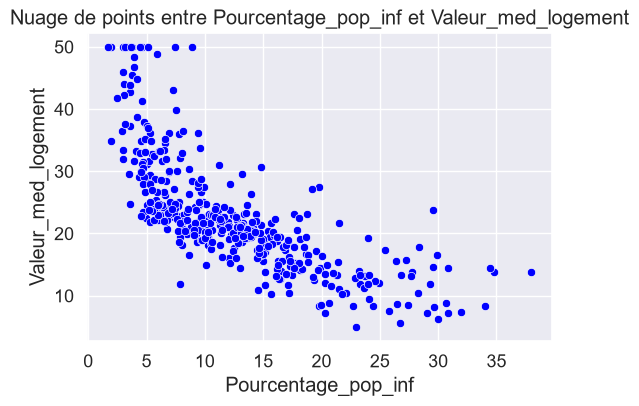

In [59]:
# Affichage des nuages de points entre la variable d'intérêt et toutes les autres variables
target_col = "Valeur_med_logement"
num_cols = list(train.select_dtypes(include=["float64", "int64"]).columns)
num_cols.remove(target_col)

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=train, x=col, y=target_col, color="blue")
    plt.title(f"Nuage de points entre {col} et {target_col}")
    plt.xlabel(col)
    plt.ylabel(target_col)
    plt.show()

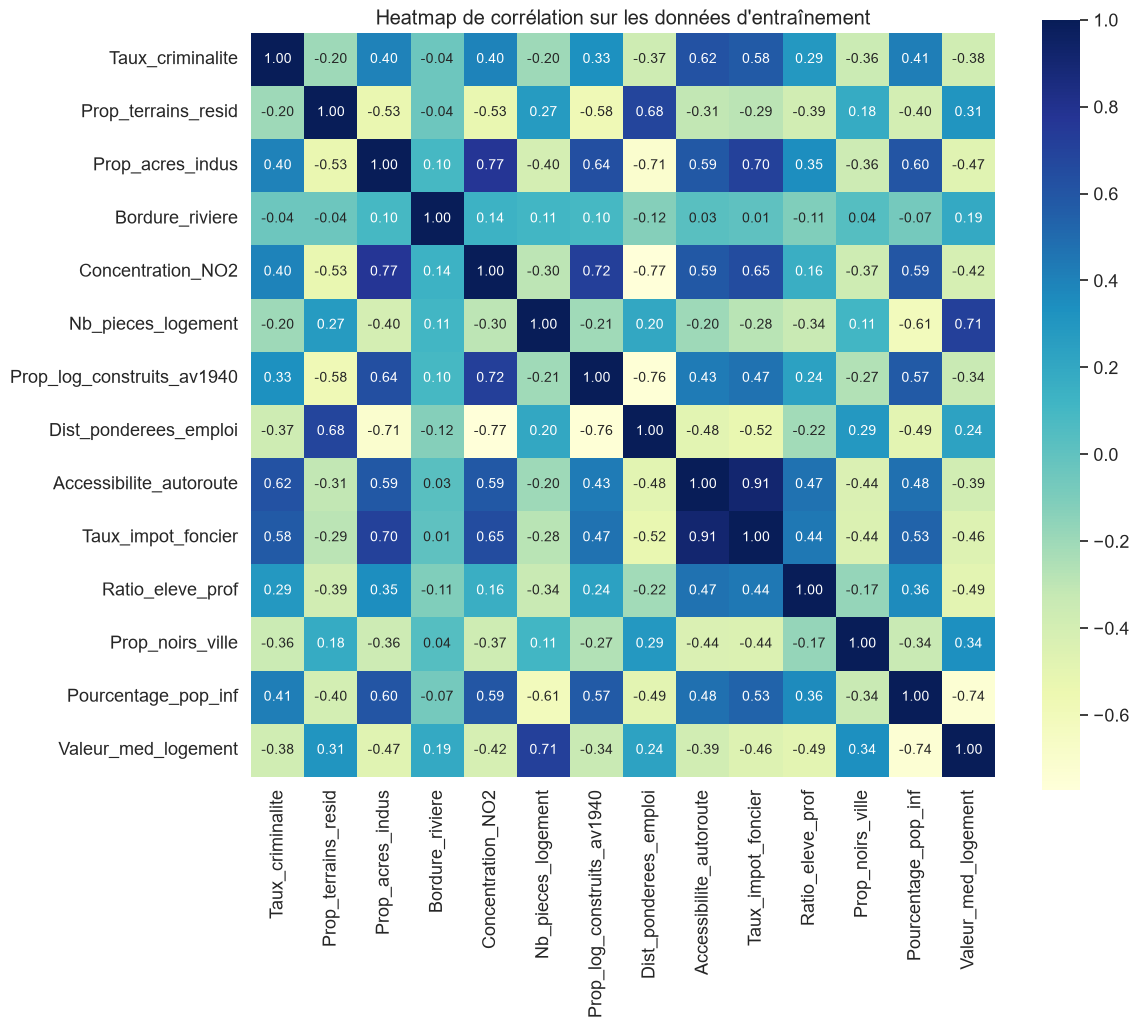

In [60]:
# Calcul de la matrice de corrélation sur les données d'entraînement
corr_matrix_train = train.corr()


sns.set(font_scale=1.2)
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_train, cmap="YlGnBu", annot=True, annot_kws={"size": 10}, square=True, fmt=".2f")

# Affichage du graphique
import matplotlib.pyplot as plt

plt.title("Heatmap de corrélation sur les données d'entraînement")
plt.show()


### Selection des variables à partir de la ocrrélation de pearson

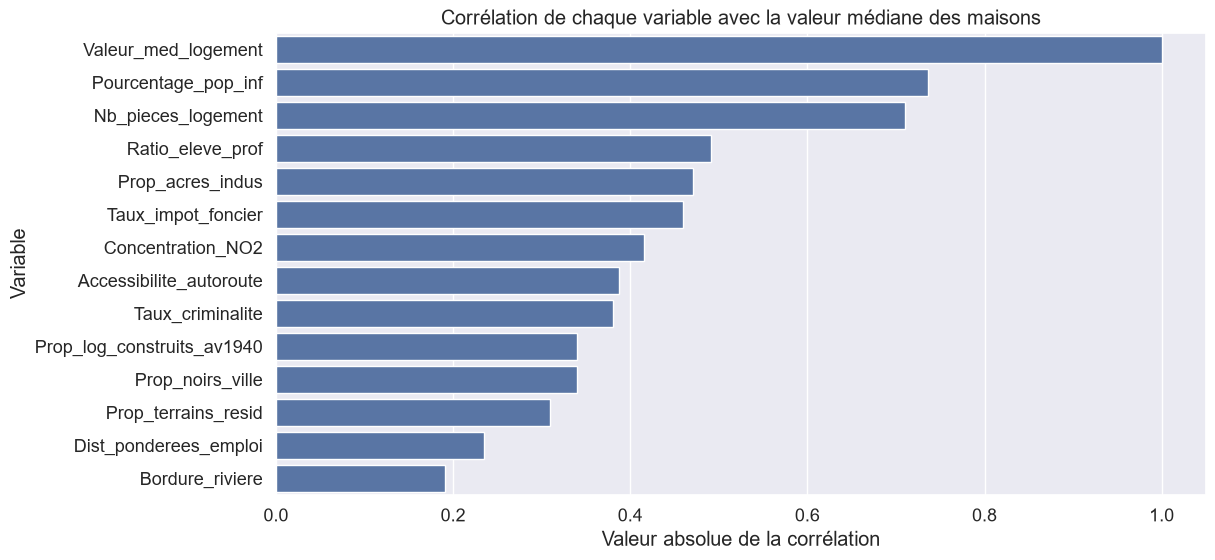

In [61]:

# Calcul de la corrélation entre chaque variable et la variable cible (en valeur absolue)
correlations = abs(train.corr()["Valeur_med_logement"]).sort_values(ascending=False)

# Représentation graphique des corrélations
plt.figure(figsize=(12, 6))
sns.barplot(x=correlations.values, y=correlations.index)
plt.xlabel("Valeur absolue de la corrélation")
plt.ylabel("Variable")
plt.title("Corrélation de chaque variable avec la valeur médiane des maisons")
plt.show()








# Modélisation sur la base train

In [62]:
import statsmodels.api as sm
# Séparation des variables prédictives et de la variable cible
X_train = train.drop("Valeur_med_logement", axis=1)
y_train = train["Valeur_med_logement"]


X_test = test.drop("Valeur_med_logement", axis=1)
y_test = test["Valeur_med_logement"]

# Fit du modèle linéaire
lr_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()

# Obtention du tableau de résultats
results_table = lr_model.summary2().tables[1]
results_table

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,30.246751,5.676806,5.328128,1.681610e-07,19.085779,41.407723
Taux_criminalite,-0.113056,0.034784,-3.250225,1.253280e-03,-0.181444,-0.044668
Prop_terrains_resid,0.030110,0.015996,1.882358,6.053164e-02,-0.001339,0.061560
Prop_acres_indus,0.040381,0.067365,0.599432,5.492330e-01,-0.092063,0.172825
Bordure_riviere,2.784438,0.955688,2.913544,3.779273e-03,0.905494,4.663382
Concentration_NO2,-17.202633,4.236119,-4.060942,5.909342e-05,-25.531120,-8.874147
Nb_pieces_logement,4.438835,0.463980,9.566874,1.285223e-19,3.526621,5.351050
Prop_log_construits_av1940,-0.006296,0.014568,-0.432204,6.658322e-01,-0.034938,0.022345
Dist_ponderees_emploi,-1.447865,0.225950,-6.407891,4.258552e-10,-1.892099,-1.003632
Accessibilite_autoroute,0.262430,0.075986,3.453638,6.137380e-04,0.113035,0.411824


In [63]:
lr_model.summary2().tables[0]

,0,1,2,3
0,Model:,OLS,Adj. R-squared:,0.743
1,Dependent Variable:,Valeur_med_logement,AIC:,2416.6443
2,Date:,2026-10-06 02:52,BIC:,2472.6641
3,No. Observations:,404,Log-Likelihood:,-1194.3
4,Df Model:,13,F-statistic:,90.43
5,Df Residuals:,390,Prob (F-statistic):,6.21e-109
6,R-squared:,0.751,Scale:,22.418


In [64]:
# Obtention des prédictions et des métriques d'évaluation
y_train_pred = lr_model.predict(sm.add_constant(X_train))
y_test_pred = lr_model.predict(sm.add_constant(X_test))
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_train = np.sqrt(mse_train)
rmse_test = np.sqrt(mse_test)


In [65]:
# Construction du tableau de résultats

df_metrics = pd.DataFrame({
    'Métrique': ['R2', 'MSE', 'RMSE'],
    'Train': [r2_train, mse_train, rmse_train],
    'Test': [r2_test, mse_test, rmse_test]
})

print(df_metrics)



  Métrique      Train       Test
0       R2   0.750886   0.668759
1      MSE  21.641413  24.291119
2     RMSE   4.652033   4.928602


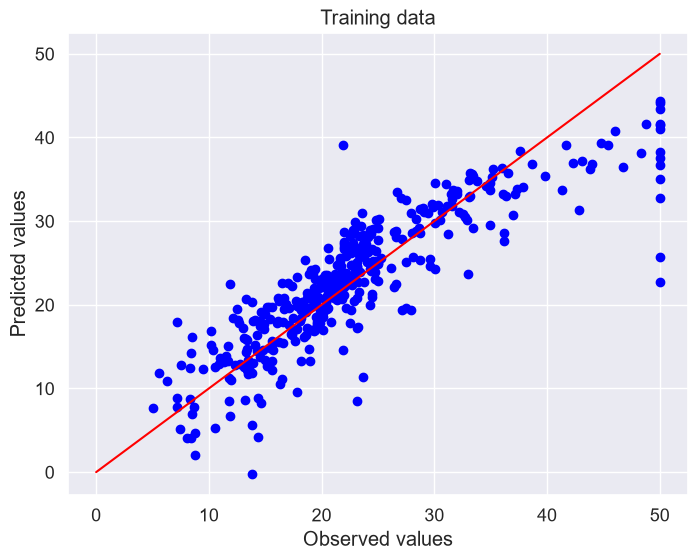

In [66]:

# Tracer les valeurs observées en fonction des valeurs prédites sur les données d'entraînement
plt.figure(figsize=(8, 6))
plt.scatter(y_train, y_train_pred, color='blue')
plt.xlabel('Observed values')
plt.ylabel('Predicted values')
plt.title('Training data')
plt.plot(np.arange(0, 55, 5), np.arange(0, 55, 5), color='red')
plt.show()



## Vérification des hypothèses du modèles

### Vérification de l'homoscédasticité

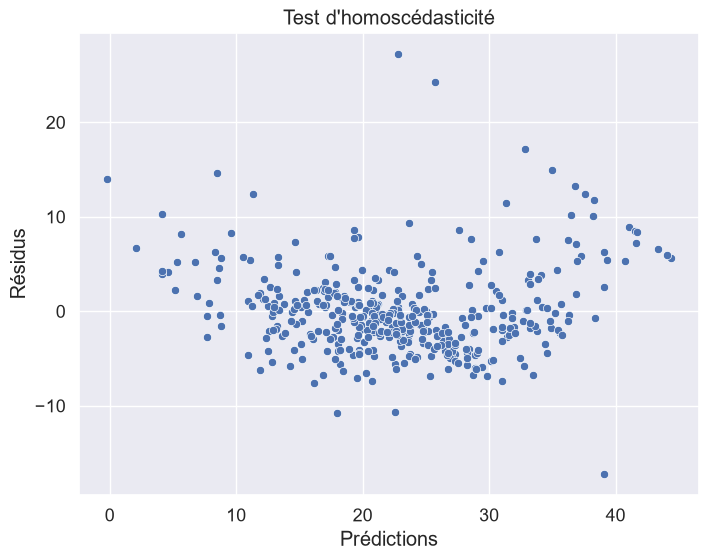

In [67]:
# Test d'homoscédasticité
y_train_pred = lr_model.predict(sm.add_constant(X_train))
residuals = y_train - y_train_pred

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_train_pred, y=residuals)
plt.title("Test d'homoscédasticité")
plt.xlabel("Prédictions")
plt.ylabel("Résidus")
plt.show()

In [68]:
# Test de Breusch-Pagan
bp_test = sm.stats.diagnostic.het_breuschpagan(lr_model.resid, lr_model.model.exog)
print("Test de Breusch-Pagan : statistique = %f, p-value = %f" % (bp_test[0], bp_test[1]))

Test de Breusch-Pagan : statistique = 59.189087, p-value = 0.000000


### Vérification de la multicolinéarité

In [69]:
# Test de multicollinéarité
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
vif["features"] = X_train.columns
print(vif)

    VIF Factor                    features
0     1.713187            Taux_criminalite
1     2.465631         Prop_terrains_resid
2     3.877855            Prop_acres_indus
3     1.096674             Bordure_riviere
4     4.469150           Concentration_NO2
5     1.947809          Nb_pieces_logement
6     2.989948  Prop_log_construits_av1940
7     4.168578       Dist_ponderees_emploi
8     7.658316     Accessibilite_autoroute
9     8.943301          Taux_impot_foncier
10    1.851448            Ratio_eleve_prof
11    1.325121            Prop_noirs_ville
12    2.818045         Pourcentage_pop_inf


#### Tester d'autres modèles

In [70]:
train.columns

Index(['Taux_criminalite', 'Prop_terrains_resid', 'Prop_acres_indus',
       'Bordure_riviere', 'Concentration_NO2', 'Nb_pieces_logement',
       'Prop_log_construits_av1940', 'Dist_ponderees_emploi',
       'Accessibilite_autoroute', 'Taux_impot_foncier', 'Ratio_eleve_prof',
       'Prop_noirs_ville', 'Pourcentage_pop_inf', 'Valeur_med_logement'],
      dtype='str')

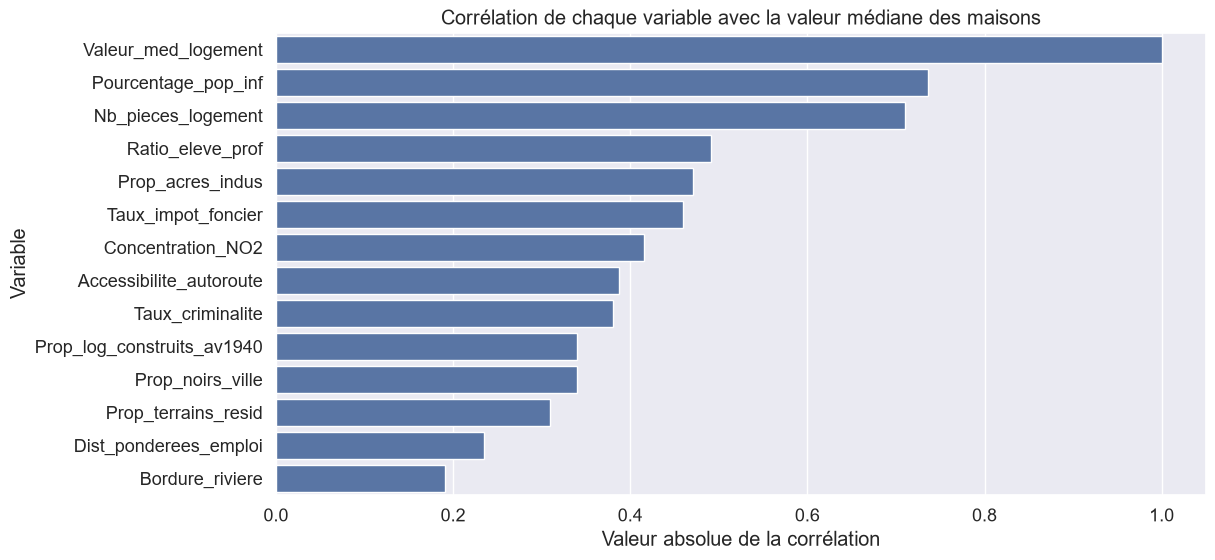

In [71]:
# Représentation graphique des corrélations
plt.figure(figsize=(12, 6))
sns.barplot(x=correlations.values, y=correlations.index)
plt.xlabel("Valeur absolue de la corrélation")
plt.ylabel("Variable")
plt.title("Corrélation de chaque variable avec la valeur médiane des maisons")
plt.show()




In [72]:
new_selection=['Taux_criminalite', 'Prop_terrains_resid','Bordure_riviere','Pourcentage_pop_inf','Nb_pieces_logement']
train_selectedb = train[new_selection]
train_selectedb["Valeur_med_logement"] = train["Valeur_med_logement"]
train_selectedb

,Taux_criminalite,Prop_terrains_resid,Bordure_riviere,Pourcentage_pop_inf,Nb_pieces_logement,Valeur_med_logement
478,15.02340,0.0,0,24.91,5.304,12.0
16,0.62739,0.0,0,8.47,5.834,19.9
333,0.03466,35.0,0,7.83,6.031,19.4
424,7.05042,0.0,0,23.29,6.103,13.4
20,0.72580,0.0,0,11.28,5.727,18.2
...,...,...,...,...,...,...
107,0.17120,0.0,0,18.66,5.836,19.5
271,0.29916,20.0,0,13.00,5.856,21.1
349,0.01501,80.0,0,5.99,6.635,24.5
436,11.16040,0.0,0,23.27,6.629,13.4


In [73]:
import statsmodels.api as sm
# Séparation des variables prédictives et de la variable cible
X_train = train_selectedb.drop("Valeur_med_logement", axis=1)
y_train = train_selectedb["Valeur_med_logement"]

# Fit du modèle linéaire
lr_modelb = sm.OLS(y_train, sm.add_constant(X_train)).fit()

# Obtention du tableau de résultats
results_table = lr_modelb.summary2().tables[1]
results_table


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,-4.456849,3.443081,-1.294436,1.962652e-01,-11.225747,2.312049
Taux_criminalite,-0.120726,0.033224,-3.633660,3.160255e-04,-0.186042,-0.055409
Prop_terrains_resid,0.003962,0.012645,0.313352,7.541775e-01,-0.020897,0.028821
Bordure_riviere,3.973362,1.044607,3.803690,1.649393e-04,1.919724,6.027000
Pourcentage_pop_inf,-0.556914,0.053248,-10.458859,8.813015e-23,-0.661596,-0.452231
Nb_pieces_logement,5.430066,0.480523,11.300332,7.177379e-26,4.485386,6.374746


In [74]:
lr_modelb.summary2().tables[0]

,0,1,2,3
0,Model:,OLS,Adj. R-squared:,0.669
1,Dependent Variable:,Valeur_med_logement,AIC:,2509.9140
2,Date:,2026-10-06 02:52,BIC:,2533.9225
3,No. Observations:,404,Log-Likelihood:,-1249.0
4,Df Model:,5,F-statistic:,164.2
5,Df Residuals:,398,Prob (F-statistic):,2.14e-94
6,R-squared:,0.674,Scale:,28.790


In [75]:
vif = pd.DataFrame()
vif["VIF Factor"] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
vif["features"] = X_train.columns
print(vif)

   VIF Factor             features
0    1.217054     Taux_criminalite
1    1.199691  Prop_terrains_resid
2    1.020250      Bordure_riviere
3    2.006551  Pourcentage_pop_inf
4    1.626789   Nb_pieces_logement


In [76]:
import statsmodels.api as sm
# Séparation des variables prédictives et de la variable cible
X_train = train.drop("Valeur_med_logement", axis=1)
y_train = train["Valeur_med_logement"]

# Fit du modèle linéaire
lr_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()

# Obtention du tableau de résultats
results_table = lr_model.summary2().tables[1]
results_table

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,30.246751,5.676806,5.328128,1.681610e-07,19.085779,41.407723
Taux_criminalite,-0.113056,0.034784,-3.250225,1.253280e-03,-0.181444,-0.044668
Prop_terrains_resid,0.030110,0.015996,1.882358,6.053164e-02,-0.001339,0.061560
Prop_acres_indus,0.040381,0.067365,0.599432,5.492330e-01,-0.092063,0.172825
Bordure_riviere,2.784438,0.955688,2.913544,3.779273e-03,0.905494,4.663382
Concentration_NO2,-17.202633,4.236119,-4.060942,5.909342e-05,-25.531120,-8.874147
Nb_pieces_logement,4.438835,0.463980,9.566874,1.285223e-19,3.526621,5.351050
Prop_log_construits_av1940,-0.006296,0.014568,-0.432204,6.658322e-01,-0.034938,0.022345
Dist_ponderees_emploi,-1.447865,0.225950,-6.407891,4.258552e-10,-1.892099,-1.003632
Accessibilite_autoroute,0.262430,0.075986,3.453638,6.137380e-04,0.113035,0.411824


### Vérification de la normalité

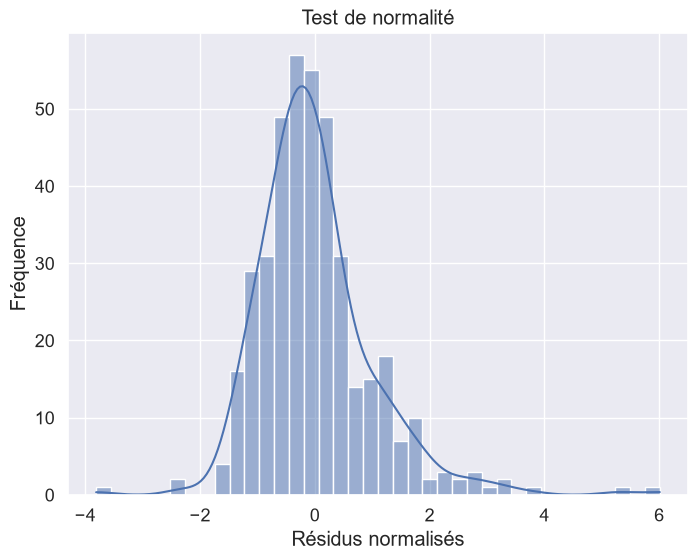

In [77]:
# Test de normalité
resid_norm = lr_model.get_influence().resid_studentized_internal
plt.figure(figsize=(8, 6))
sns.histplot(resid_norm, kde=True)
plt.title('Test de normalité')
plt.xlabel('Résidus normalisés')
plt.ylabel('Fréquence')
plt.show()


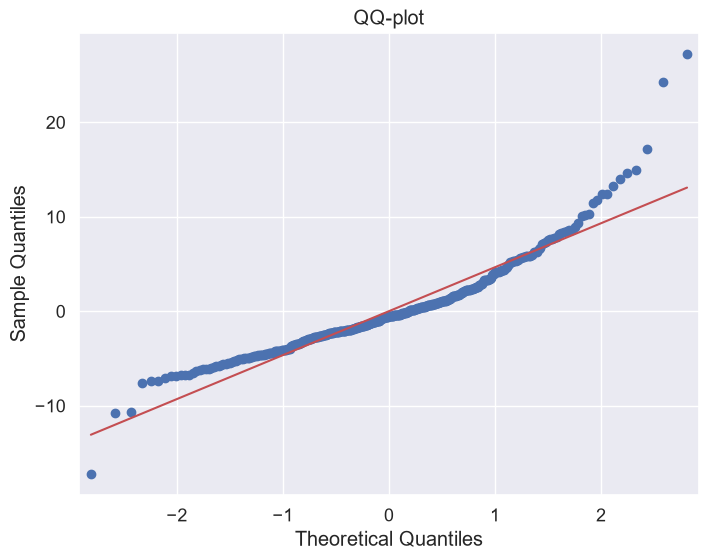

In [78]:
# QQ-plot
fig, ax = plt.subplots(figsize=(8, 6))
sm.qqplot(residuals, line='s', ax=ax)
ax.set_title('QQ-plot')
plt.show()

In [79]:
import scipy.stats as stats

# Test de Shapiro-Wilk
shapiro_test = stats.shapiro(residuals)

# Test d'Anderson-Darling
anderson_test = stats.anderson(residuals, dist='norm')

# Test de Kolmogorov-Smirnov
ks_test = stats.kstest(residuals, 'norm')

# Mettre les résultats dans un dataframe
df_normality = pd.DataFrame({
    'Test de normalité': ['Shapiro-Wilk', 'Anderson-Darling', 'Kolmogorov-Smirnov'],
    'Statistique': [shapiro_test.statistic, anderson_test.statistic, ks_test.statistic],
    'p-value': [shapiro_test.pvalue, 'N/A', ks_test.pvalue]
})

# Afficher le tableau
print(df_normality)

    Test de normalité  Statistique p-value
0        Shapiro-Wilk     0.911794     0.0
1    Anderson-Darling     7.412841     N/A
2  Kolmogorov-Smirnov     0.347848     0.0


C:\Users\EMPEREUR DALIKAN\AppData\Local\Temp\ipykernel_12520\1971233040.py:7: FutureWarning: As of SciPy 1.17, users must choose a p-value calculation method by providing the `method` parameter. `method='interpolate'` interpolates the p-value from pre-calculated tables; `method` may also be an instance of `MonteCarloMethod` to approximate the p-value via Monte Carlo simulation. When `method` is specified, the result object will include a `pvalue` attribute and not attributes `critical_value`, `significance_level`, or `fit_result`. Beginning in 1.19.0, these other attributes will no longer be available, and a p-value will always be computed according to one of the available `method` options.
  anderson_test = stats.anderson(residuals, dist='norm')


### Vérification de l'autocorrélation

In [80]:
from statsmodels.stats.stattools import durbin_watson
# Test d'autocorrélation
dw_test = durbin_watson(lr_model.resid)
print("Test de Durbin-Watson : statistique = %f" % dw_test)

Test de Durbin-Watson : statistique = 2.114123


### Moyenne des termes d'erreur

In [81]:
residuals.mean()

np.float64(-3.407615224097015e-14)